### RaschPy global MFRM worked example

This notebook works through a sample Rasch analysis of a simulated data set (200 persons, 8 items with a maximum score of 5, all rated by 8 raters, no missing data), taking you through the relevant commands step by step, with notes before each cell. Relevant outputs will appear below each cell.

Import the modules and set the working directory (here called `my_working_directory`) to where you want to save your output files.

In [1]:
import raschpy as rp
import pandas as pd
import os

os.chdir('my_working_directory')

**A note on data validation**

Every model constructor validates the item-response network automatically at instantiation (`validate=True` by default) and warns if it's disconnected — if there's no chain of persons and items linking every item to every other, the resulting item locations aren't on a common scale, even though `calibrate()` will still run without error. This is worth seeing happen once. Here we build a small, deliberately disconnected data set: two groups of persons who each only answer a disjoint set of items, with no item shared between the groups to link them:

In [2]:
sim_disconnected = rp.MFRM_Sim_Global(no_of_items=8, no_of_persons=40, no_of_facet_elements=4, max_score=5, seed=99)
responses_disconnected = sim_disconnected.responses.copy()
persons = responses_disconnected.index.get_level_values(1).unique()
group_a, group_b = persons[:20], persons[20:]
responses_disconnected.loc[(slice(None), group_a), responses_disconnected.columns[4:]] = float('nan')   # group A: only items 1-4
responses_disconnected.loc[(slice(None), group_b), responses_disconnected.columns[:4]] = float('nan')    # group B: only items 5-8

broken_mfrm = rp.MFRM(responses_disconnected)   # raises a UserWarning

/Users/markelliott/Documents/RaschPy-dev/raschpy/mfrm.py:903: UserWarning: The response data is disconnected into 2 separate sub-networks, with no empirical comparisons spanning them: Sub-group 1 (size 4): ['Item_1', 'Item_2', 'Item_3', 'Item_4']; Sub-group 2 (size 4): ['Item_5', 'Item_6', 'Item_7', 'Item_8']. Items in different sub-networks cannot be placed on a single scale -- each sub-network's estimates are identified only up to its own origin -- and un-smoothed calibration breaks down.
  self.connectivity_status = self.check_data_connectivity()


`connectivity_status` records the diagnosis, including which items ended up in which isolated sub-group:

In [3]:
broken_mfrm.connectivity_status

{'connected': False,
 'components_count': 2,
 'isolated_items': [],
 'all_sub_groups': [['Item_1', 'Item_2', 'Item_3', 'Item_4'],
  ['Item_5', 'Item_6', 'Item_7', 'Item_8']],
 'directionally_isolated_items': [],
 'strongly_connected': False}

The rest of this notebook uses a single, fully-connected simulated data set, so this warning won't come up again.

Simulate a data set. Passing `seed=999` makes the simulation fully reproducible — rerunning this notebook will always generate the same data set. 12 items, 8 raters, 200 persons, no missing data.

In [4]:
sim = rp.MFRM_Sim_Global(no_of_items=12, no_of_persons=200, no_of_facet_elements=8, max_score=5, missing=0, seed=999)
sim.responses.to_csv('mfrm_global_scores.csv')

If you have your own response data saved to a CSV file instead of simulating it, use `loadup_mfrm_single()` to load and validate it (for a single file with a (Rater, Person) MultiIndex — see `loadup_mfrm_xlsx_tabs()`/`loadup_mfrm_multiple()` for one-sheet-per-rater or one-file-per-rater layouts). Demonstrated here by reloading the file we just saved:

In [5]:
data, invalid_responses = rp.loadup_mfrm_single('mfrm_global_scores.csv', max_score=5)

Check the data - view the first two lines

In [6]:
data.head(2)

Item_1  Item_2  Item_3  Item_4  Item_5  Item_6  Item_7  \
Rater   Person                                                             
Rater_1 Person_1     3.0     3.0     3.0     3.0     0.0     3.0     4.0   
        Person_2     0.0     1.0     3.0     1.0     1.0     2.0     1.0   

                  Item_8  Item_9  Item_10  Item_11  Item_12  
Rater   Person                                               
Rater_1 Person_1     4.0     3.0      3.0      2.0      3.0  
        Person_2     3.0     3.0      1.0      2.0      1.0

Check for any invalid responses (not usable for estimation purposes and excluded)

In [7]:
invalid_responses

,,Item_1,Item_2,Item_3,Item_4,Item_5,Item_6,Item_7,Item_8,Item_9,Item_10,Item_11,Item_12
Rater,Person,,,,,,,,,,,,


Create an MFRM object. Passing the simulation object `sim` directly (rather than the reloaded `data`) attaches the generating parameters under `mfrm.generating`, which lets us check parameter recovery further down. If you're analysing your own data, pass a DataFrame instead (e.g. `rp.MFRM(data)`).

In [8]:
mfrm = rp.MFRM(sim)

Calibrate under the global rater parameterisation (a single global effect per rater). The `%%time` "magic function" returns the time taken to run the cell contents (algorithm run time in this case).

To run the analysis using conditional maximum likelihood (CML) estimation (Andersen, 1970), pass `estimation='cml'` to `calibrate_global()`. The methods that follow use the fit's estimation.

In [9]:
%%time
mfrm.calibrate_global()

CPU times: user 16.9 ms, sys: 1.59 ms, total: 18.5 ms
Wall time: 18.3 ms


Check the item location estimates - view the first two items

In [10]:
mfrm.items.head(2)

Item_1    0.917063
Item_2    0.336052
dtype: float64

Since this is simulated data, we know the true generating item, threshold, rater and person parameters, and can check how closely the calibration recovered them using `recovery_stats()`. This produces a recovery plot per parameter type (generating vs. estimated, with identity/OLS/Huber fit lines) and a summary table (RMSE, MAE, bias, Pearson correlation, SD ratio, OLS/Huber regression slopes, an OLS-vs-Huber divergence flag, and the proportion of parameters flagged as significantly different from their generating value) — for items, thresholds, category widths, raters, and persons all in one call. Person recovery uses a pseudo-estimate construction (Elliott & Buttery, 2022a) rather than comparing directly against the true person location — this isolates estimation/model-specification error from the irreducible noise of a single finite response pattern, which a naive true-vs-estimated comparison would otherwise be dominated by. Results are stored in `mfrm.recovery` (e.g. `mfrm.recovery.items.summary`, `mfrm.recovery.thresholds.summary`, `mfrm.recovery.category_widths.summary`, `mfrm.recovery.raters.subvectors['global'].summary`, `mfrm.recovery.persons.summary`).

`model=` defaults to whichever model the data was generated under (`'global'` here), so a bare `mfrm.recovery_stats()` call is enough — but it can also be passed a *different* model to deliberately study the person-measurement cost of model misspecification (fitting a simpler or different rater model than the one the data actually came from), following Elliott & Buttery (2022a).

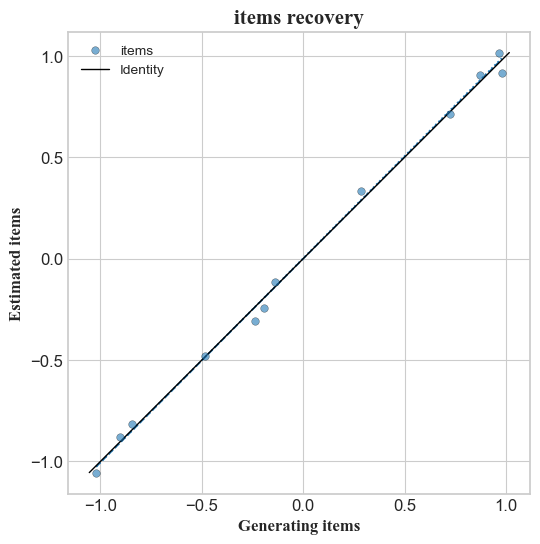

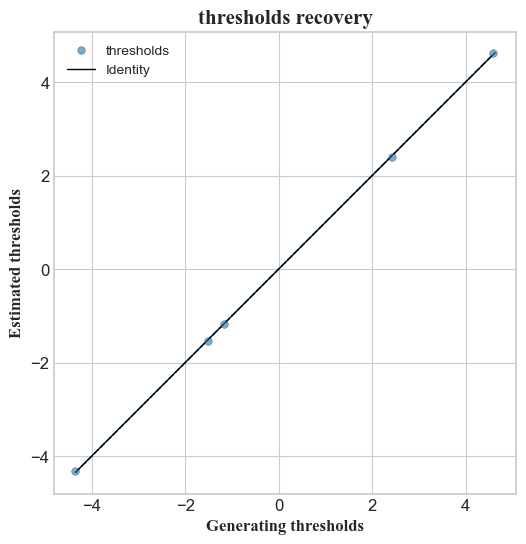

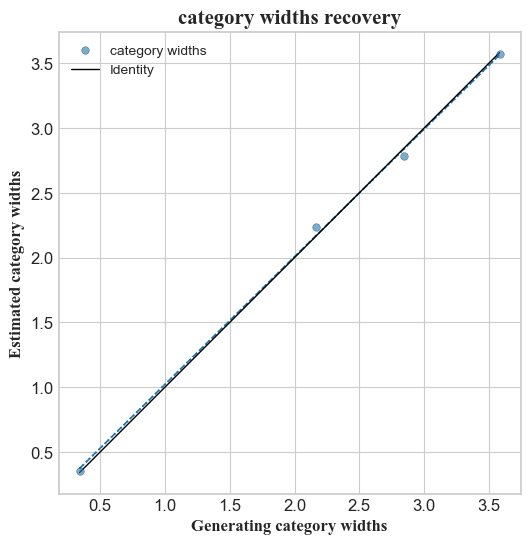

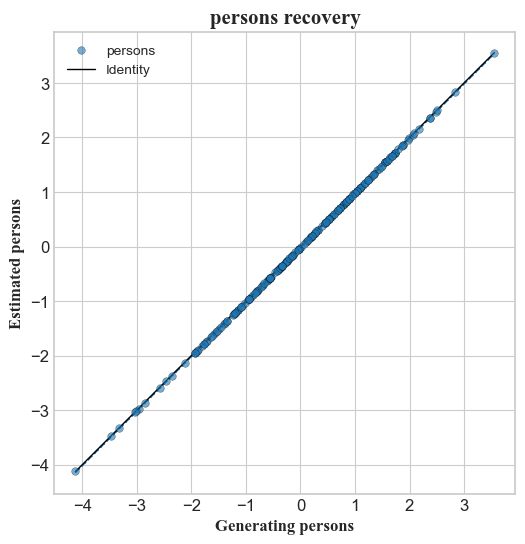

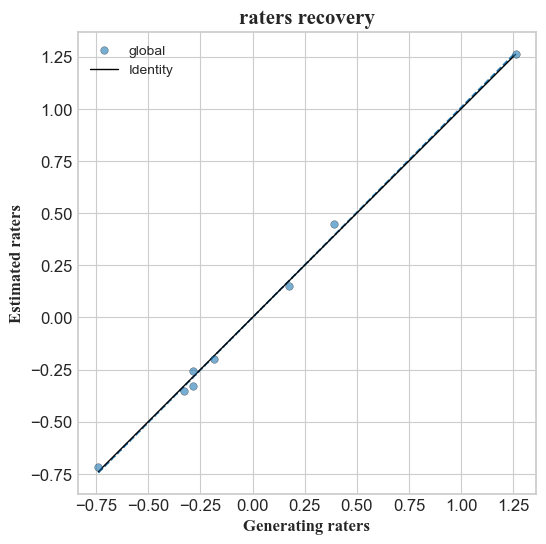

,Overall
RMSE,0.040988
MAE,0.036404
bias,0.0
r,0.998401
r_squared,0.996805
SD_ratio,1.006822
OLS_slope,1.005212
OLS_intercept,0.0
Huber_slope,1.007292
Huber_intercept,0.002584


In [11]:
mfrm.recovery_stats(filename='my_mfrm_global_recovery')
mfrm.recovery.items.summary

Generate a table of item statistics (and check run time), and save to file

In [12]:
%%time
mfrm.item_stats_df_global(full=True, filename='mfrm_global_item_stats')

CPU times: user 2.95 ms, sys: 641 μs, total: 3.59 ms
Wall time: 5 ms


,Estimate,SE,2.5%,97.5%,Count,Facility,Infit MS,Infit Z,Outfit MS,Outfit Z,PM corr,Exp PM corr
Item_1,0.917,0.035,0.849,0.986,1600,0.438,0.988,-0.322,0.962,-1.065,0.652,0.658
Item_2,0.336,0.036,0.266,0.406,1600,0.495,0.982,-0.501,0.989,-0.302,0.654,0.648
Item_3,-0.478,0.037,-0.550,-0.406,1600,0.567,1.011,0.329,1.009,0.266,0.633,0.630
Item_4,0.714,0.035,0.645,0.784,1600,0.459,0.966,-0.957,0.969,-0.872,0.665,0.655
Item_5,1.016,0.038,0.942,1.091,1600,0.428,0.982,-0.509,0.999,-0.025,0.658,0.659
Item_6,-0.116,0.036,-0.187,-0.044,1600,0.537,0.983,-0.486,0.989,-0.287,0.639,0.638
Item_7,-0.241,0.036,-0.312,-0.170,1600,0.546,1.061,1.711,1.059,1.639,0.641,0.635
Item_8,-1.055,0.041,-1.136,-0.974,1600,0.614,0.942,-1.674,0.947,-1.505,0.646,0.619
Item_9,-0.814,0.037,-0.886,-0.741,1600,0.596,0.955,-1.294,0.964,-1.015,0.622,0.623
Item_10,-0.307,0.039,-0.383,-0.231,1600,0.552,0.946,-1.556,0.937,-1.809,0.641,0.634


Check the item statistics table

Generate a table of threshold statistics (and check run time), and save to file

In [13]:
%%time
mfrm.threshold_stats_df_global(full=True, filename='mfrm_global_threshold_stats')

CPU times: user 1.2 ms, sys: 383 μs, total: 1.58 ms
Wall time: 2.31 ms


,Estimate,SE,2.5%,97.5%,Infit MS,Infit Z,Outfit MS,Outfit Z,Discrim,PM corr,Exp PM corr
Threshold 1,-4.318,0.069,-4.455,-4.182,0.988,-0.330,1.022,0.334,1.012,0.378,0.361
Threshold 2,-1.531,0.036,-1.602,-1.460,0.985,-1.320,0.981,-0.972,1.037,0.648,0.636
Threshold 3,-1.175,0.033,-1.241,-1.110,0.999,-0.089,0.993,-0.332,1.004,0.846,0.841
Threshold 4,2.395,0.038,2.320,2.469,0.988,-0.932,0.997,-0.115,1.012,0.761,0.754
Threshold 5,4.630,0.075,4.483,4.777,0.961,-0.714,0.971,-0.243,1.017,0.204,0.215


Check the threshold statistics table

And the same recovery check for thresholds (already computed together with item recovery above, via the same `recovery_stats()` call — its plot appeared alongside the others):

In [14]:
mfrm.recovery.thresholds.summary

,Overall
RMSE,0.028962
MAE,0.027604
bias,0.0
r,0.999958
r_squared,0.999917
SD_ratio,1.001298
OLS_slope,1.001256
OLS_intercept,0.0
Huber_slope,1.001256
Huber_intercept,0.0


`recovery_stats()` also checks category-width recovery (a separate parameter type from raw threshold locations) as a bonus over the old notebook's checks:

In [15]:
mfrm.recovery.category_widths.summary

,Overall
RMSE,0.045344
MAE,0.038297
bias,0.00326
r,0.999387
r_squared,0.998774
SD_ratio,0.98565
OLS_slope,0.985046
OLS_intercept,0.036665
Huber_slope,0.985104
Huber_intercept,0.035239


Generate a table of rater statistics (and check run time), and save to file

In [16]:
%%time
mfrm.rater_stats_df_global(filename='mfrm_global_rater_stats')

CPU times: user 2.77 ms, sys: 624 μs, total: 3.4 ms
Wall time: 4.61 ms


,Estimate,SE,Count,Infit MS,Outfit MS
Rater_1,1.261,0.030,2400,0.959,0.944
Rater_2,0.150,0.029,2400,1.005,1.014
Rater_3,-0.198,0.030,2400,1.001,1.010
Rater_4,0.447,0.026,2400,0.989,0.985
Rater_5,-0.719,0.031,2400,1.022,1.021
Rater_6,-0.331,0.026,2400,0.972,0.964
Rater_7,-0.354,0.031,2400,0.969,0.964
Rater_8,-0.257,0.030,2400,0.969,0.968


Check the rater statistics table

And the same recovery check for rater global effects (already computed together with item recovery above, via the same `recovery_stats()` call). For the `global` model this is a single sub-vector; models with more than one rater sub-vector (e.g. `bivector`, `bistretch`) would show one key per sub-vector under `mfrm.recovery.raters.subvectors`:

In [17]:
mfrm.recovery.raters.subvectors['global'].summary

,Overall
RMSE,0.031027
MAE,0.026149
bias,-0.0
r,0.99858
r_squared,0.997162
SD_ratio,1.008333
OLS_slope,1.006902
OLS_intercept,-0.0
Huber_slope,1.004477
Huber_intercept,-0.001677


Generate a table of person statistics (and check run time), and save to file

In [18]:
%%time
mfrm.person_stats_df_global(full=True, filename='mfrm_global_person_stats')

CPU times: user 3.55 ms, sys: 575 μs, total: 4.12 ms
Wall time: 5.66 ms


,Estimate,CSEM,RSEM,Score,Max score,p,Infit MS,Outfit MS,Infit Z,Outfit Z
Person_1,1.395,0.172,0.181,309,480,0.644,1.101,1.041,0.650,0.293
Person_2,-0.697,0.140,0.142,225,480,0.469,1.025,1.002,0.225,0.062
Person_3,-2.975,0.150,0.140,105,480,0.219,0.873,0.872,-0.849,-0.848
Person_4,-0.038,0.152,0.155,256,480,0.533,1.043,1.095,0.325,0.597
Person_5,0.756,0.167,0.157,287,480,0.598,0.886,0.889,-0.635,-0.593
...,...,...,...,...,...,...,...,...,...,...
Person_196,-0.175,0.149,0.140,250,480,0.521,0.880,0.923,-0.768,-0.413
Person_197,0.128,0.156,0.136,263,480,0.548,0.766,0.750,-1.529,-1.531
Person_198,1.455,0.172,0.174,311,480,0.648,1.019,1.033,0.167,0.252
Person_199,-1.946,0.135,0.146,157,480,0.327,1.159,1.112,1.193,0.831


Check the person statistics table - view the first ten persons with `.head(10)`

And the same recovery check for person locations (already computed together with the others above, via the same `recovery_stats()` call — its plot appeared alongside the others). This uses the Elliott & Buttery (2022a) pseudo-estimate construction, not a direct comparison against `mfrm.generating.persons`:

In [19]:
mfrm.recovery.persons.summary

,Overall
RMSE,0.01613
MAE,0.015892
bias,-0.015725
r,0.999996
r_squared,0.999993
SD_ratio,0.999952
OLS_slope,0.999949
OLS_intercept,-0.015724
Huber_slope,1.000272
Huber_intercept,-0.016756


Generate a table of test-level statistics (and check run time), and save to file

In [20]:
%%time
mfrm.test_stats_df_global(filename='mfrm_global_test_stats')

CPU times: user 618 μs, sys: 411 μs, total: 1.03 ms
Wall time: 1.49 ms


,Items,Persons
Mean,0.000,-0.003
SD,0.754,1.332
Separation ratio,20.223,8.586
Strata,27.297,11.782
Reliability,0.998,0.987


Check the test statistics table

Run an item residual correlation analysis (and check run time), and save relevant output to file

In [21]:
%%time
mfrm.item_res_corr_analysis_global()
mfrm.item_residual_correlations_global.to_csv('mfrm_global_item_residual_correlations.csv')
mfrm.item_loadings_global.to_csv('mfrm_global_item_loadings.csv')

CPU times: user 1.58 ms, sys: 493 μs, total: 2.07 ms
Wall time: 4 ms


View the table of pairwise item standard residual correlations

In [22]:
round(mfrm.item_residual_correlations_global, 3)

,Item_1,Item_2,Item_3,Item_4,Item_5,Item_6,Item_7,Item_8,Item_9,Item_10,Item_11,Item_12
Item_1,1.000,-0.053,-0.022,-0.047,-0.034,-0.001,-0.000,-0.018,0.005,-0.029,-0.003,-0.031
Item_2,-0.053,1.000,0.020,-0.009,-0.021,0.011,-0.030,-0.001,-0.028,-0.020,-0.034,-0.034
Item_3,-0.022,0.020,1.000,-0.028,0.001,-0.008,0.024,0.023,-0.010,-0.027,0.029,-0.031
Item_4,-0.047,-0.009,-0.028,1.000,-0.035,-0.036,-0.028,-0.051,0.000,-0.017,-0.029,-0.026
Item_5,-0.034,-0.021,0.001,-0.035,1.000,-0.004,0.010,-0.024,-0.042,-0.043,-0.018,-0.003
Item_6,-0.001,0.011,-0.008,-0.036,-0.004,1.000,-0.046,0.008,-0.032,-0.005,-0.019,0.000
Item_7,-0.000,-0.030,0.024,-0.028,0.010,-0.046,1.000,-0.038,-0.045,-0.004,0.023,-0.030
Item_8,-0.018,-0.001,0.023,-0.051,-0.024,0.008,-0.038,1.000,-0.016,-0.025,0.028,-0.022
Item_9,0.005,-0.028,-0.010,0.000,-0.042,-0.032,-0.045,-0.016,1.000,0.030,-0.027,-0.035
Item_10,-0.029,-0.020,-0.027,-0.017,-0.043,-0.005,-0.004,-0.025,0.030,1.000,-0.038,-0.038


View the item loadings on the first principal component of the pairwise standard residual correlations (dimensionality test)

In [23]:
round(mfrm.item_loadings_global['PC 1'], 3)

Item_1     0.018
Item_2    -0.041
Item_3    -0.307
Item_4     0.417
Item_5    -0.288
Item_6    -0.155
Item_7    -0.081
Item_8    -0.277
Item_9     0.460
Item_10    0.395
Item_11   -0.453
Item_12   -0.298
Name: PC 1, dtype: float64

Run a rater residual correlation analysis (and check run time), and save relevant output to file

In [24]:
%%time
mfrm.rater_res_corr_analysis_global()
mfrm.rater_residual_correlations_global.to_csv('mfrm_global_rater_residual_correlations.csv')
mfrm.rater_loadings_global.to_csv('mfrm_global_rater_loadings.csv')

CPU times: user 7.67 ms, sys: 842 μs, total: 8.51 ms
Wall time: 10.3 ms


View the table of pairwise rater standard residual correlations

In [25]:
round(mfrm.rater_residual_correlations_global, 3)

,Rater_1,Rater_2,Rater_3,Rater_4,Rater_5,Rater_6,Rater_7,Rater_8
Rater_1,1.000,-0.023,0.000,-0.006,-0.008,0.007,-0.007,-0.038
Rater_2,-0.023,1.000,-0.022,0.003,-0.026,-0.010,-0.001,-0.022
Rater_3,0.000,-0.022,1.000,0.026,-0.002,-0.004,-0.009,-0.042
Rater_4,-0.006,0.003,0.026,1.000,-0.043,-0.023,-0.007,0.019
Rater_5,-0.008,-0.026,-0.002,-0.043,1.000,-0.033,-0.013,-0.037
Rater_6,0.007,-0.010,-0.004,-0.023,-0.033,1.000,-0.018,-0.025
Rater_7,-0.007,-0.001,-0.009,-0.007,-0.013,-0.018,1.000,-0.038
Rater_8,-0.038,-0.022,-0.042,0.019,-0.037,-0.025,-0.038,1.000


View the rater loadings on the first principal component of the pairwise standard residual correlations (dimensionality test)

In [26]:
round(mfrm.rater_loadings_global['PC 1'], 3)

Rater_1   -0.284
Rater_2    0.316
Rater_3   -0.401
Rater_4    0.244
Rater_5   -0.403
Rater_6   -0.052
Rater_7   -0.315
Rater_8    0.647
Name: PC 1, dtype: float64

Produce an item characteristic curve (item response function) curve for Item 2, with observed category means plotted and the central item location marked

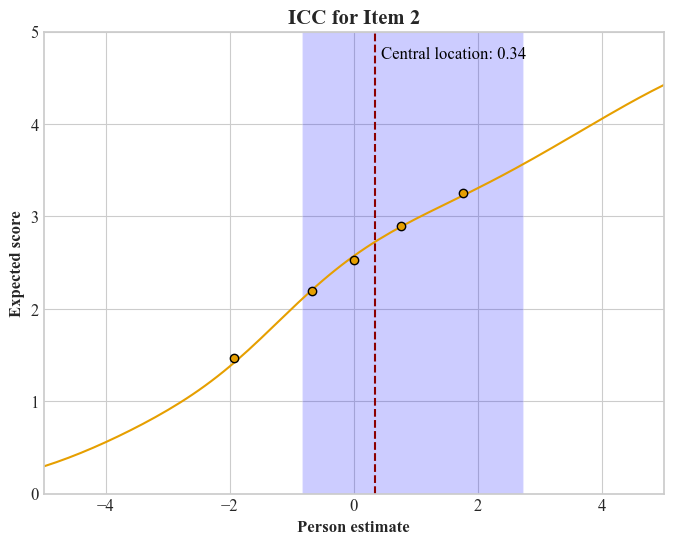

In [27]:
mfrm.icc_global('Item_2', title='ICC for Item 2', obs=True, central_location=True, cat_highlight=3,
                xmin=-5, xmax=5, filename='my_mfrm_global_icc')

Produce a set of category response curves for Item 2, with category 1 highlighted and the thresholds marked

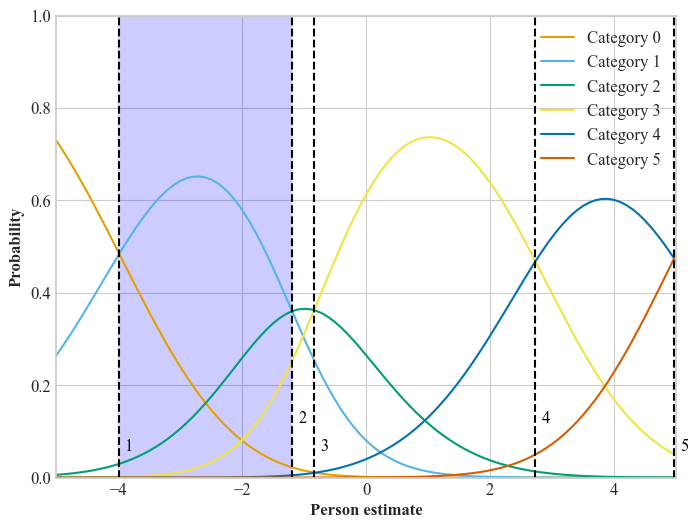

In [28]:
mfrm.crcs_global('Item_2', thresh_lines=True, cat_highlight=1, xmin=-5, xmax=5, filename='my_mfrm_global_crcs')

Produce a set of threshold characteristic curves for Item 2, with observed category means plotted for threshold 5, category 1 highlighted and the thresholds marked

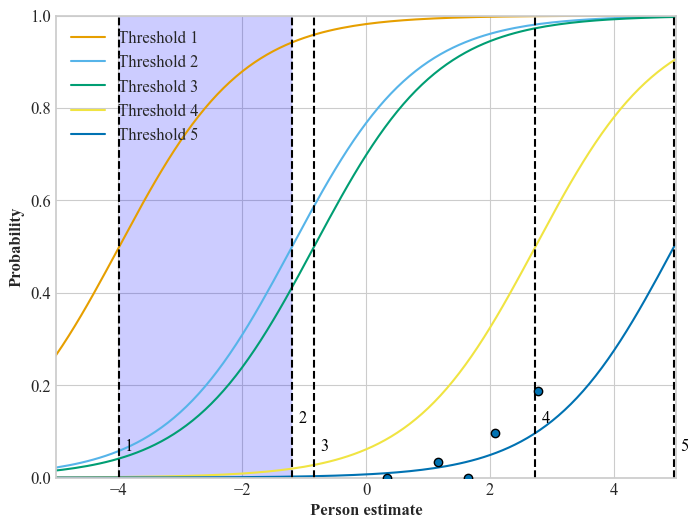

In [29]:
mfrm.threshold_ccs_global('Item_2', thresh_lines=True, obs=[5], cat_highlight=1, xmin=-5, xmax=5, filename='my_mfrm_global_threshold_ccs')

Produce an item information function curve for Item 2

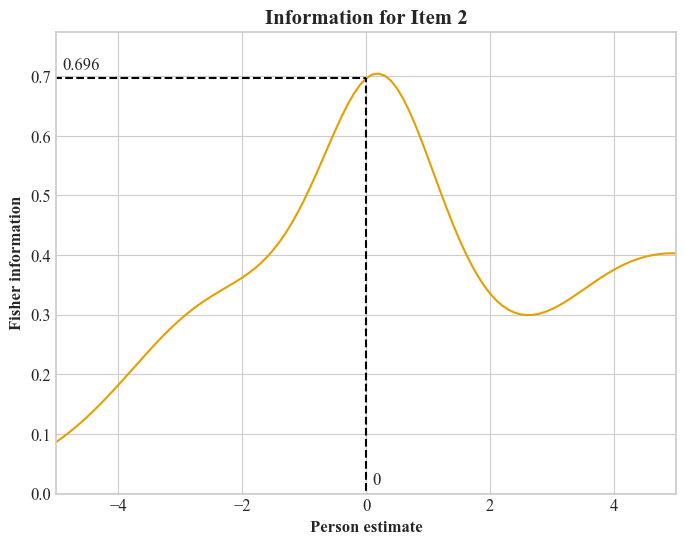

In [30]:
mfrm.iic_global('Item_2', point_info_lines=[0], point_info_labels=True, title='Information for Item 2',
                xmin=-5, xmax=5, filename='my_mfrm_global_iic')

Produce a test characteristic curve (test response function), with person locations corresponding to scores of 150 and 250 (aggregated across all raters) plotted.

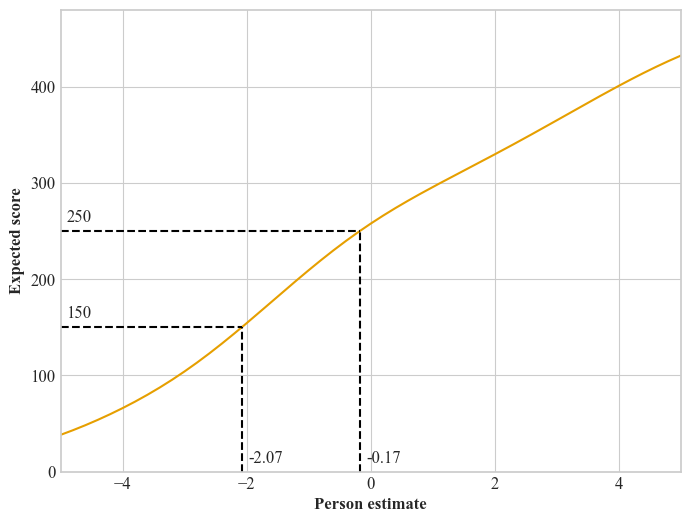

In [31]:
mfrm.tcc_global(score_lines=[150, 250], score_labels=True, filename='my_mfrm_global_tcc')

Produce a test information curve

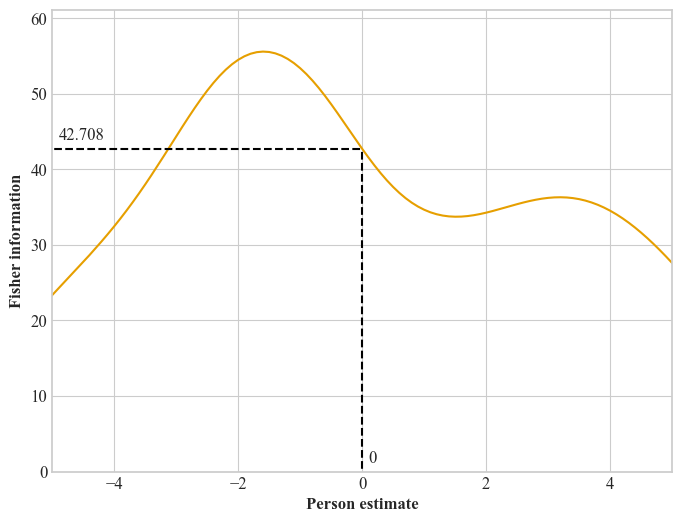

In [32]:
mfrm.test_info_global(point_info_lines=[0], point_info_labels=True, filename='my_mfrm_global_test_info_curve')

Produce a test CSEM (conditional standard error of measurement) curve, with the CSEM corresponding to a person location of -3 plotted

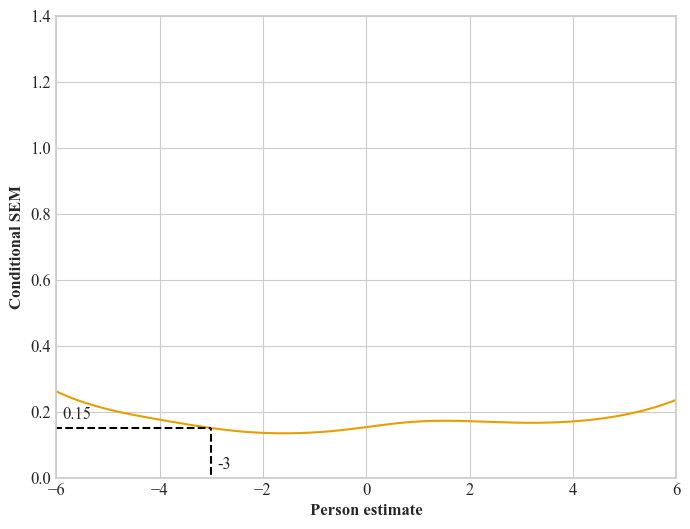

In [33]:
mfrm.test_csem_global(point_csem_lines=[-3], point_csem_labels=True, ymax=1.4, xmin=-6, xmax=6, filename='my_mfrm_global_csem_curve')

Produce a histogram of standardised residuals, with a normal distribution curve overlaid

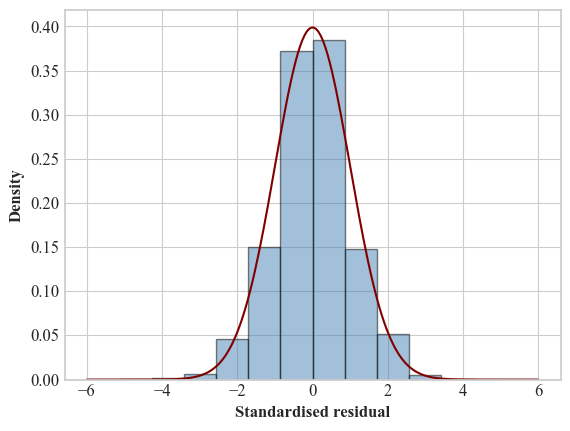

In [34]:
mfrm.std_residuals_plot_global(bin_width=0.6, normal=True, filename='my_mfrm_global_std_residuals_plot')

Now run an anchored analysis, anchoring to the average of Raters 1-4 (e.g. a set of 'gold standard' raters).

In [35]:
%%time
anchors = ['Rater_1', 'Rater_2', 'Rater_3', 'Rater_4']
mfrm.calibrate_global_anchor(anchors)

CPU times: user 414 μs, sys: 5 μs, total: 419 μs
Wall time: 418 μs


Check the anchored rater global effects against the unanchored ones.

In [36]:
rater_check = pd.DataFrame({'Unanchored': mfrm.raters_global,
                            'Anchored': mfrm.anchor_raters_global})
round(rater_check, 3)

,Unanchored,Anchored
Rater_1,1.261,0.846
Rater_2,0.150,-0.265
Rater_3,-0.198,-0.613
Rater_4,0.447,0.032
Rater_5,-0.719,-1.134
Rater_6,-0.331,-0.746
Rater_7,-0.354,-0.769
Rater_8,-0.257,-0.673


Produce a Wright map (unanchored), showing the person location distribution alongside an item strip (one row per item, divided into its own category segments at each Rasch-Andrich threshold) and a rater panel, with mean/±1SD/±2SD reference marks for persons

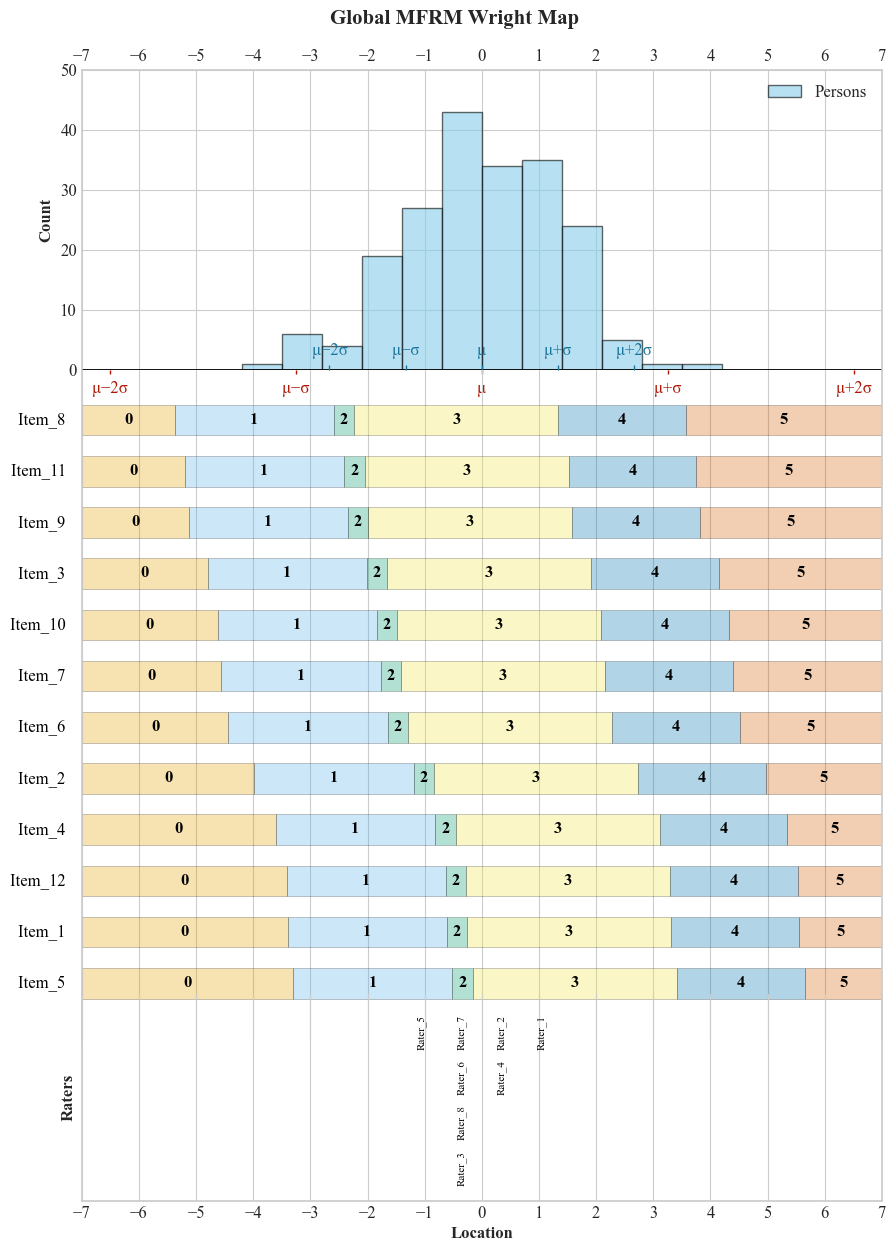

In [37]:
mfrm.wright_map_global(item_strip=True, facet_labels=True, distribution_markers=True, title='Global MFRM Wright Map', filename='my_mfrm_global_wright_map')

#### References

Andersen, E. B. (1970). Asymptotic properties of conditional maximum-likelihood estimators. *Journal of the Royal Statistical Society, Series B*, 32(2), 283–301.